<a href="https://colab.research.google.com/github/akshu88/Applied-ML-Lab/blob/main/Exp_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score,f1_score

# **1. Load the dataset**

In [ ]:
df = pd.read_csv('restaurant_reviews_1000.csv').drop_duplicates(subset="review").dropna()

In [ ]:
df.head()

,review,sentiment,label
0,I really enjoyed this restaurant; the salad ta...,positive,1
1,I would gladly return because the sandwich was...,positive,1
2,"The meal was pleasant, fresh, and reasonably p...",positive,1
3,I would gladly return because the curry was ou...,positive,1
4,I will not return because the salad was bland ...,negative,0


In [ ]:
print("Shape: ", df.shape)

Shape:  (638, 3)


In [ ]:
print(df["label"].value_counts())  # 1 = positive , 0 = negative

label
1    324
0    314
Name: count, dtype: int64


# **2. Split into Train and Test**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(df["review"], df["label"], test_size=0.2, random_state = 42, stratify=df["label"])

# **3. Convert text to numbers with TF-IDF**

In [ ]:
tfidf = TfidfVectorizer(ngram_range=(1,2), max_features=5000)
X_train = tfidf.fit_transform(X_train)
X_test = tfidf.transform(X_test)

# **4.The four Models**

In [ ]:
models = {
    "Naive Bayes":MultinomialNB(),
    "Logistic Regression":LogisticRegression(max_iter=1000),
    "SVM":LinearSVC(),
    "Random Forest":RandomForestClassifier(random_state=42),
}

# **5. Train each model adn record its scores**

In [ ]:
results=[]
for name,model in models.items():
  model.fit(X_train,y_train)
  pred = model.predict(X_test)
  results.append({
      "Model":name,
      "Accuracy":accuracy_score(y_test,pred),
      "Precision":precision_score(y_test,pred),
      "Recall":recall_score(y_test,pred),
      "F1 Score":f1_score(y_test,pred)
  })

# **6. Comparison Table(best model first)**

In [ ]:
results = pd.DataFrame(results).sort_values(["Accuracy", "F1 Score"], ascending=False)
print("\n", results.round(4).to_string(index=False))


               Model  Accuracy  Precision  Recall  F1 Score
        Naive Bayes       1.0        1.0     1.0       1.0
Logistic Regression       1.0        1.0     1.0       1.0
                SVM       1.0        1.0     1.0       1.0
      Random Forest       1.0        1.0     1.0       1.0


# **7. Bar chart of all metrics**

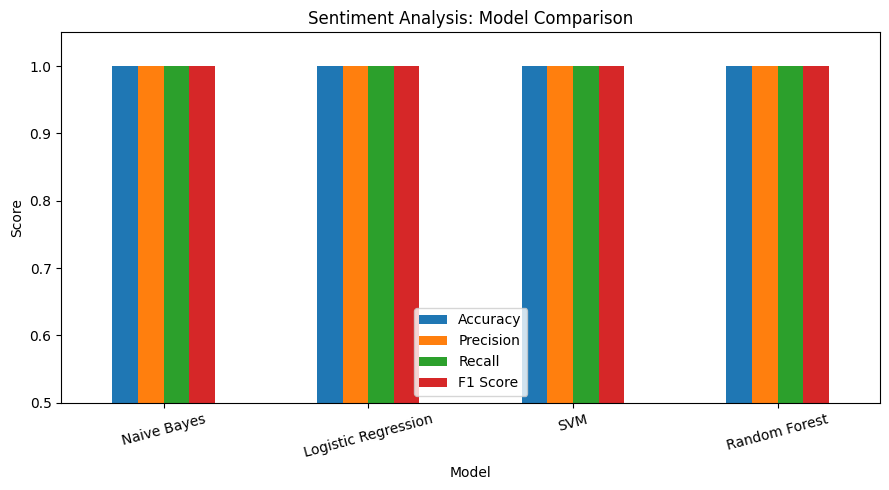

In [ ]:
results.set_index("Model").plot(kind="bar", figsize=(9, 5), ylim=(0.5, 1.05))
plt.title("Sentiment Analysis: Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

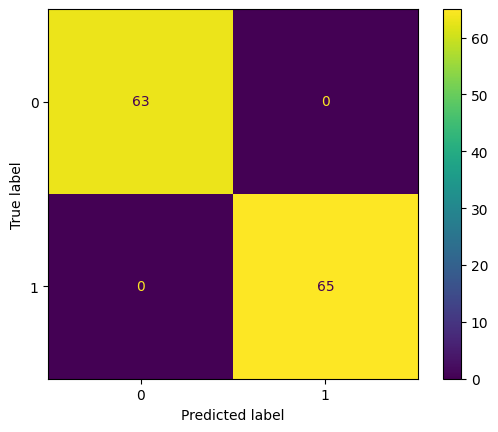

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test, pred);
plt.show()